In [17]:
import warnings
warnings.filterwarnings("ignore")

In [18]:
# ---- LSTM -------
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

vocab_size = 10000
max_len = 200
keras.utils.set_random_seed(42)

print("All libraries loaded")

All libraries loaded


In [ ]:
# Load the IMDB dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.imdb.load_data(num_words=vocab_size)

lengths = np.array([len(r) for r in x_train])
print("Review length (tokens)  min / median / max:", lengths.min(), "/", int(np.median(lengths)), "/", lengths.max())
print("Reviews longer than max_len =", max_len, ":", int((lengths > max_len).sum()), "of", len(x_train))
print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)

Review length (tokens)  min / median / max: 11 / 178 / 2494
Reviews longer than max_len = 200 : 10677 of 25000
x_train shape: (25000,)
x_test shape: (25000,)


In [ ]:
# Preprocessing
x_train = keras.utils.pad_sequences(x_train, maxlen=max_len, padding="post", truncating="pre")
x_test = keras.utils.pad_sequences(x_test, maxlen=max_len, padding="post", truncating="pre")
print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)



x_train shape: (25000, 200)
x_test shape: (25000, 200)


In [4]:
print("Number of training reviews:", len(x_train))
print("Number of test reviews     :", len(x_test))

print("\nFirst review as raw token IDs (first 20):", x_train[0][:20])
print("Label of first review:", y_train[0], "(0 = negative, 1 = positive)")

Number of training reviews: 25000
Number of test reviews     : 25000

First review as raw token IDs (first 20): [  5  25 100  43 838 112  50 670   2   9  35 480 284   5 150   4 172 112
 167   2]
Label of first review: 1 (0 = negative, 1 = positive)


In [5]:
# Decode IDs back to words (needs the word index file; if it cannot be downloaded we simply show IDs)
try:
    word_index = keras.datasets.imdb.get_word_index()
    index_from = 3  # Keras reserves 0,1,2 (pad, start, unknown)
    id_to_word = {i + index_from: w for w, i in word_index.items()}
    id_to_word.update({0: "<PAD>", 1: "<START>", 2: "<UNK>"})
    def decode(ids):
        return " ".join(id_to_word.get(int(i), "?") for i in ids)
    print(decode(x_train[0][:60]))
    HAVE_WORDS = True
except Exception as e:
    print("Could not load the word index (", type(e).__name__, "). Continuing with token IDs only.")
    HAVE_WORDS = False
    def decode(ids):
        return str(list(map(int, ids)))

and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the


In [6]:
model = keras.Sequential([
    layers.Input(shape=(max_len,)),
    layers.Embedding(input_dim=vocab_size, output_dim=64, mask_zero=True),
    layers.SpatialDropout1D(0.3),
    layers.LSTM(64, dropout=0.2),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 200, 64)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Model parameters calculation
emb_params = vocab_size * 64
lstm_params = 4 * 64 * (64 + 64 + 1)
hidden_params = 64 * 32 + 32
out_params = 32 * 1 + 1
print("Embedding:", emb_params, "| LSTM:", lstm_params, "| Dense(32):", hidden_params, "| Dense(1):", out_params,
      "| Total:", emb_params + lstm_params + hidden_params + out_params)
print("Keras says total:", model.count_params())


Embedding: 640000 | LSTM: 33024 | Dense(32): 2080 | Dense(1): 33 | Total: 675137
Keras says total: 675137


In [ ]:
# Train the model
history = model.fit(x_train, y_train,
                    epochs=20,
                    batch_size=32, 
                    validation_split=0.2,
                    callbacks=[early_stop],
                    )

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 100s 145ms/step - accuracy: 0.7814 - loss: 0.4518 - val_accuracy: 0.8680 - val_loss: 0.3258
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 91s 146ms/step - accuracy: 0.8874 - loss: 0.2853 - val_accuracy: 0.8808 - val_loss: 0.2958
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 133ms/step - accuracy: 0.9165 - loss: 0.2240 - val_accuracy: 0.8768 - val_loss: 0.3476
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 129ms/step - accuracy: 0.9271 - loss: 0.1945 - val_accuracy: 0.8736 - val_loss: 0.3551
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.


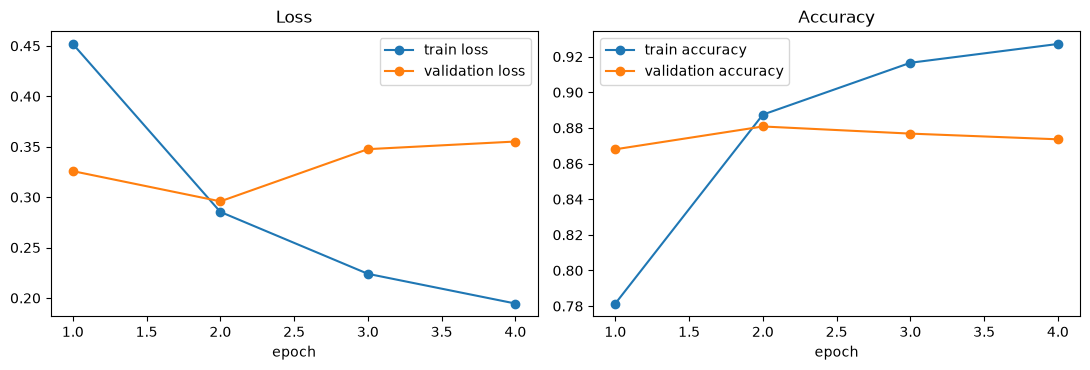

In [ ]:
# Training curve
import matplotlib.pyplot as plt

hist = history.history
epochs_range = range(1, len(hist["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(epochs_range, hist["loss"], marker="o", label="train loss")
ax[0].plot(epochs_range, hist["val_loss"], marker="o", label="validation loss")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(epochs_range, hist["accuracy"], marker="o", label="train accuracy")
ax[1].plot(epochs_range, hist["val_accuracy"], marker="o", label="validation accuracy")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# Evaluate the model on the test set
test_result = model.evaluate(x_test, y_test, verbose=0, return_dict=True)
print(test_result)

{'accuracy': 0.8686000108718872, 'loss': 0.31612664461135864}


In [ ]:
# Sample predictions
probs =  model.predict(x_test, verbose=0).ravel()
THRESHOLD = 0.5
preds = (probs >= THRESHOLD).astype(int)

print("Sample predictions (first 5 test reviews)")
for i in range(5):
    label = "positive" if preds[i] == 1 else "negative"
    truth = "positive" if y_test[i] == 1 else "negative"
    print(f"#{i} P(positive)={probs[i]:.3f} predicted={label:8s} {'OK' if preds[i]==y_test[i] else 'WRONG'}")


Sample predictions (first 5 test reviews)
#0 P(positive)=0.144 predicted=negative OK
#1 P(positive)=0.988 predicted=positive OK
#2 P(positive)=0.937 predicted=positive OK
#3 P(positive)=0.223 predicted=negative OK
#4 P(positive)=0.998 predicted=positive OK


Confusion matrix (rows = actual, columns = predicted):
 [[10844  1656]
 [ 1629 10871]]


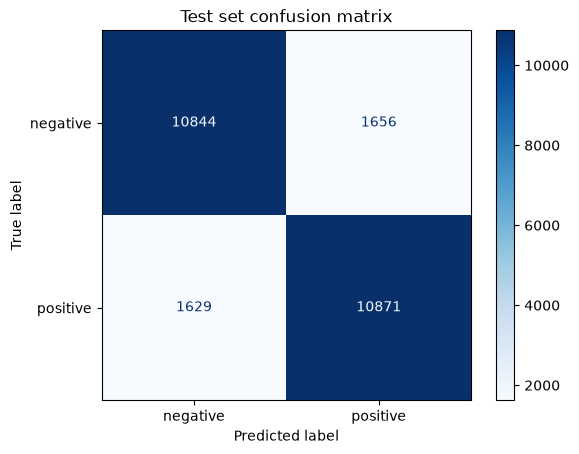

Precision (positive class): 0.868
Recall    (positive class): 0.87
F1        (positive class): 0.869

              precision    recall  f1-score   support

    negative       0.87      0.87      0.87     12500
    positive       0.87      0.87      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000



In [12]:
# Confusion matrix
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, preds)
print("Confusion matrix (rows = actual, columns = predicted):\n", cm)

ConfusionMatrixDisplay(cm,display_labels=["negative", "positive"]).plot(cmap="Blues")
plt.title("Test set confusion matrix"); plt.show()

print("Precision (positive class):", round(precision_score(y_test, preds), 3))
print("Recall    (positive class):", round(recall_score(y_test, preds), 3))
print("F1        (positive class):", round(f1_score(y_test, preds), 3))
print()
print(classification_report(y_test, preds, target_names=["negative", "positive"]))

In [ ]:
# Show the misclassified test reviews
wrong = np.where(preds != y_test)[0]
print("Number of misclassified test reviews:", len(wrong), "out of", len(y_test))

# Show the 3 most confidently wrong ones (probability far from the true label)
confidence_gap = np.abs(probs[wrong] - y_test[wrong])
worst = wrong[np.argsort(-confidence_gap)][:3]

for i in worst:
    truth = "positive" if y_test[i] == 1 else "negative"
    print(f"\n--- test review #{i} | actual: {truth} | P(positive)={probs[i]:.3f}")
    ids = x_test[i][x_test[i] != 0][:120]       # drop padding, show the first 120 tokens
    print(decode(ids) + (" ..." if (x_test[i] != 0).sum() > 120 else ""))

Number of misclassified test reviews: 3285 out of 25000

--- test review #10596 | actual: negative | P(positive)=1.000
the main lead kent is wonderful the cinematography and direction excellent and the script hugely entertaining and thought provoking with some nice set ups and witty dialogue br br the ending was a bit sudden with no conclusion given to characters and events once the finale came to its gripping end but perhaps that's what the filmmakers were going for it certainly did make the movie more unsettling i did like the fact that the main character never came to terms with his mother on screen it leaves you wondering whether or not he ever will as in real life sometimes these things are never settled this was a good choice to leave it <UNK> rather than <UNK> <UNK> it ...

--- test review #11971 | actual: negative | P(positive)=1.000
roughly and brought to our screens phillip alan mrs jones vienna br br then in 1980 the film version hit the cinemas now when it did sadly richard

In [14]:
def encode_text(text):
    # Encode like Keras IMDb: start token 1, words offset by 3, unknown / rare words -> 2
    ids = [1]
    for w in text.lower().replace(".", " ").replace(",", " ").replace("!", " ").replace("?", " ").split():
        idx = word_index.get(w)
        ids.append(idx + 3 if (idx is not None and idx + 3 < vocab_size) else 2)
    return ids

if HAVE_WORDS:
    my_reviews = [
        "this movie was wonderful and the acting was brilliant",
        "a boring and terrible film i want my time back",
        "not bad at all",
    ]
    enc = keras.utils.pad_sequences([encode_text(t) for t in my_reviews], maxlen=max_len, padding="post", truncating="pre")
    for t, p in zip(my_reviews, model.predict(enc, verbose=0).ravel()):
        print(f"P(positive)={p:.3f}  ->  {t}")
else:
    print("Word index not available in this session, so Bonus A is skipped.")

P(positive)=0.910  ->  this movie was wonderful and the acting was brilliant
P(positive)=0.105  ->  a boring and terrible film i want my time back
P(positive)=0.159  ->  not bad at all


In [ ]:
# Threshold tuning
n_val = int(0.2 * len(x_train))                      # validation_split=0.2 -> the last 20% of the training data
x_val, y_val = x_train[-n_val:], y_train[-n_val:]
val_probs = model.predict(x_val, verbose=0).ravel()
for th in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (val_probs >= th).astype(int)
    print(f"threshold {th:.1f}  precision={precision_score(y_val, p, zero_division=0):.3f}  recall={recall_score(y_val, p, zero_division=0):.3f}  f1={f1_score(y_val, p, zero_division=0):.3f}")

threshold 0.3  precision=0.828  recall=0.919  f1=0.871
threshold 0.4  precision=0.853  recall=0.898  f1=0.875
threshold 0.5  precision=0.875  recall=0.885  f1=0.880
threshold 0.6  precision=0.894  recall=0.857  f1=0.875
threshold 0.7  precision=0.915  recall=0.822  f1=0.866


In [ ]:
# Save the model
model.save("lstm_model.keras")